In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
numerical_features = [
    "age", "trestbps", "chol",
    "thalch", "oldpeak", "ca"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "thal"
]

for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

lr_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/logistic_r_model.pkl")
knn_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")
dt_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/decision_tree_model.pkl")
rf_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")
svm_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN (K=16)": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Tuned SVM": svm_model
}

In [2]:
# print(svm_model.named_steps)
# for step_name, step in svm_model.named_steps.items():

#     print(f"\nStep: {step_name}")
#     print("Type:", type(step))

In [3]:
all_features = X_train.columns.tolist()

top_9_features = [
    "cp", "exang", "thalch", "oldpeak", "slope",
    "age", "thal", "trestbps", "sex"
]

top_7_features = [
    "cp", "exang", "thalch", "oldpeak",
    "slope", "age", "thal"
]

# print("Baseline:", len(all_features))
# print("Top 9:", len(top_9_features))
# print("Top 7:", len(top_7_features))

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC

def create_svm_pipeline(features):

    numerical_cols = [
        col for col in features
        if col in numerical_features
    ]

    categorical_cols = [
        col for col in features
        if col in categorical_features
    ]

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        ))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            C=0.1,
            kernel="linear",
            probability=True,
            random_state=42
        ))
    ])

    return pipeline

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Define experiments
experiments = {
    "All 13 Features": all_features,
    "Top 9 Features": top_9_features,
    "Top 7 Features": top_7_features
}

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}

selection_results = {}

# Run experiments
for name, features in experiments.items():

    print(f"Evaluating: {name}")

    # Create pipeline for selected features
    model = create_svm_pipeline(features)

    # Select corresponding columns
    X_selected = X_train[features]

    scores = cross_validate(
        model,
        X_selected,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    selection_results[name] = {
        "Features": len(features),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Std ROC-AUC": scores["test_roc_auc"].std(),
        "Mean F1": scores["test_f1"].mean(),
        "Std F1": scores["test_f1"].std()
    }

# Create comparison table
selection_comparison = pd.DataFrame(
    selection_results
).T

print("\nFeature Selection Comparison:")
print(selection_comparison.round(4))

Evaluating: All 13 Features
Evaluating: Top 9 Features
Evaluating: Top 7 Features

Feature Selection Comparison:
                 Features  Mean ROC-AUC  Std ROC-AUC  Mean F1  Std F1
All 13 Features      13.0        0.8966       0.0135   0.8431  0.0113
Top 9 Features        9.0        0.8753       0.0246   0.8382  0.0186
Top 7 Features        7.0        0.8663       0.0239   0.8145  0.0190


In [7]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC


# ==========================================
# 1. DEFINE FEATURE GROUPS
# ==========================================

numerical_features = [
    "age", "trestbps", "chol",
    "thalch", "oldpeak", "ca"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "thal"
]


# ==========================================
# 2. DEFINE PREPROCESSING PIPELINES
# ==========================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])


# ==========================================
# 3. CREATE INITIAL SVM PIPELINE
# ==========================================

rfe_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

rfe_svm = Pipeline([
    ("preprocessor", rfe_preprocessor),
    ("classifier", SVC(
        C=0.1,
        kernel="linear",
        probability=True,
        random_state=42
    ))
])


# ==========================================
# 4. GROUPED RFE FUNCTION
# ==========================================

def grouped_rfe(X, y, model, n_features_to_select):

    selected_features = X.columns.tolist()
    elimination_history = []

    if not 1 <= n_features_to_select <= len(selected_features):
        raise ValueError("Invalid number of features to select.")

    while len(selected_features) > n_features_to_select:

        current_num = [
            f for f in numerical_features
            if f in selected_features
        ]

        current_cat = [
            f for f in categorical_features
            if f in selected_features
        ]

        # Rebuild preprocessing using remaining features
        transformers = []

        if current_num:
            transformers.append((
                "num",
                clone(numeric_pipeline),
                current_num
            ))

        if current_cat:
            transformers.append((
                "cat",
                clone(categorical_pipeline),
                current_cat
            ))

        current_preprocessor = ColumnTransformer(
            transformers=transformers
        )

        current_model = clone(model)

        current_model.set_params(
            preprocessor=current_preprocessor
        )

        # Fit model
        current_model.fit(X[selected_features], y)

        preprocessor = current_model.named_steps["preprocessor"]
        classifier = current_model.named_steps["classifier"]

        transformed_names = preprocessor.get_feature_names_out()
        coefficients = np.abs(classifier.coef_[0])

        # Calculate importance for each original feature
        importance = {}

        for feature in selected_features:

            indices = [
                i for i, name in enumerate(transformed_names)
                if name == f"num__{feature}"
                or name.startswith(f"num__{feature}_")
                or name.startswith(f"cat__{feature}_")
            ]

            if len(indices) == 0:
                raise ValueError(
                    f"No transformed columns found for {feature}"
                )

            importance[feature] = np.linalg.norm(
                coefficients[indices]
            )

        # Remove least important feature
        least_important = min(
            importance,
            key=importance.get
        )

        elimination_history.append({
            "Removed Feature": least_important,
            "Importance": importance[least_important],
            "Remaining Features": len(selected_features) - 1
        })

        selected_features.remove(least_important)

    return selected_features, pd.DataFrame(elimination_history)


# ==========================================
# 5. RUN RFE
# ==========================================

rfe_9_features, history_9 = grouped_rfe(
    X_train,
    y_train,
    rfe_svm,
    n_features_to_select=9
)

rfe_7_features, history_7 = grouped_rfe(
    X_train,
    y_train,
    rfe_svm,
    n_features_to_select=7
)


# ==========================================
# 6. DISPLAY RESULTS
# ==========================================

print("RFE - 9 Features:")
print(rfe_9_features)

print("\nRFE - 7 Features:")
print(rfe_7_features)

print("\nElimination History - 9 Features:")
display(history_9)

print("\nElimination History - 7 Features:")
display(history_7)


RFE - 9 Features:
['age', 'sex', 'cp', 'fbs', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

RFE - 7 Features:
['sex', 'cp', 'fbs', 'exang', 'slope', 'ca', 'thal']

Elimination History - 9 Features:


,Removed Feature,Importance,Remaining Features
0,trestbps,0.041175,12
1,restecg,0.123479,11
2,thalch,0.174795,10
3,chol,0.173359,9



Elimination History - 7 Features:


,Removed Feature,Importance,Remaining Features
0,trestbps,0.041175,12
1,restecg,0.123479,11
2,thalch,0.174795,10
3,chol,0.173359,9
4,oldpeak,0.213772,8
5,age,0.208231,7


In [9]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.base import clone
import pandas as pd


# ==========================================
# 1. CREATE A PIPELINE FOR ANY FEATURE SET
# ==========================================

def create_svm_pipeline(features):

    selected_num = [
        f for f in numerical_features if f in features
    ]

    selected_cat = [
        f for f in categorical_features if f in features
    ]

    transformers = []

    if selected_num:
        transformers.append((
            "num",
            clone(numeric_pipeline),
            selected_num
        ))

    if selected_cat:
        transformers.append((
            "cat",
            clone(categorical_pipeline),
            selected_cat
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            C=0.1,
            kernel="linear",
            probability=True,
            random_state=42
        ))
    ])

    return model


# ==========================================
# 2. DEFINE FIVE EXPERIMENTS
# ==========================================

experiments = {
    "All 13 Features": X_train.columns.tolist(),
    "Top 9 MI Features": top_9_features,
    "Top 7 MI Features": top_7_features,
    "Top 9 RFE Features": rfe_9_features,
    "Top 7 RFE Features": rfe_7_features
}


# ==========================================
# 3. CROSS-VALIDATION CONFIGURATION
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}


# ==========================================
# 4. RUN EXPERIMENTS
# ==========================================

selection_results = {}

for name, features in experiments.items():

    print(f"Evaluating: {name}")

    model = create_svm_pipeline(features)

    X_selected = X_train[features]

    scores = cross_validate(
        model,
        X_selected,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    selection_results[name] = {
        "Features": len(features),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Std ROC-AUC": scores["test_roc_auc"].std(),
        "Mean F1": scores["test_f1"].mean(),
        "Std F1": scores["test_f1"].std()
    }


# ==========================================
# 5. DISPLAY COMPARISON
# ==========================================

selection_comparison = pd.DataFrame(
    selection_results
).T

print("\nFeature Selection Comparison:")

display(selection_comparison.round(4))


Evaluating: All 13 Features
Evaluating: Top 9 MI Features
Evaluating: Top 7 MI Features
Evaluating: Top 9 RFE Features
Evaluating: Top 7 RFE Features

Feature Selection Comparison:


,Features,Mean ROC-AUC,Std ROC-AUC,Mean F1,Std F1
All 13 Features,13.0,0.8959,0.0138,0.8384,0.0097
Top 9 MI Features,9.0,0.8749,0.0259,0.8392,0.0213
Top 7 MI Features,7.0,0.8658,0.0240,0.8127,0.0177
Top 9 RFE Features,9.0,0.8988,0.0202,0.8396,0.0149
Top 7 RFE Features,7.0,0.8913,0.0172,0.8256,0.0220


In [11]:
# Full feature set
all_13_features = X_train.columns.tolist()

# RFE-selected feature set
rfe_9_features = rfe_9_features

print("13 Features:", all_13_features)
print("9 RFE Features:", rfe_9_features)
import joblib

# Create separate pipelines
svm_13_model = create_svm_pipeline(all_13_features)
svm_9_rfe_model = create_svm_pipeline(rfe_9_features)

# Train on complete training data
svm_13_model.fit(X_train[all_13_features], y_train)

svm_9_rfe_model.fit(X_train[rfe_9_features], y_train)

joblib.dump(
    svm_13_model,
    "D:/1_Python Programmes/Projects/HDD/models/svm_all_13_features.pkl"
)

joblib.dump(
    svm_9_rfe_model,
    "D:/1_Python Programmes/Projects/HDD/models/svm_rfe_9_features.pkl"
)

# Save feature lists too
joblib.dump(
    all_13_features,
    "D:/1_Python Programmes/Projects/HDD/models/all_13_features.pkl"
)

joblib.dump(
    rfe_9_features,
    "D:/1_Python Programmes/Projects/HDD/models/rfe_9_features.pkl"
)

print("Both SVM models and feature lists saved successfully!")

13 Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
9 RFE Features: ['age', 'sex', 'cp', 'fbs', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Both SVM models and feature lists saved successfully!


In [14]:
svm_13_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_all_13_features.pkl")
svm_9_rfe_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_rfe_9_features.pkl")

all_13_features = joblib.load("D:/1_Python Programmes/Projects/HDD/models/all_13_features.pkl")
rfe_9_features = joblib.load("D:/1_Python Programmes/Projects/HDD/models/rfe_9_features.pkl")

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

models_to_compare = {
    "SVM - All 13 Features": (
        svm_13_model,
        all_13_features
    ),
    "SVM - RFE 9 Features": (
        svm_9_rfe_model,
        rfe_9_features
    )
}

comparison_results = {}

for name, (model, features) in models_to_compare.items():

    X_test_selected = X_test[features]

    # Predictions
    y_pred = model.predict(X_test_selected)

    # Probability of positive class
    y_prob = model.predict_proba(X_test_selected)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    comparison_results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": tn / (tn + fp),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

# Comparison table
final_comparison = pd.DataFrame(
    comparison_results
).T

display(final_comparison.round(4))

,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
SVM - All 13 Features,0.8370,0.7951,0.9510,0.6951,0.8661,0.9103
SVM - RFE 9 Features,0.8152,0.7615,0.9706,0.6220,0.8534,0.9103


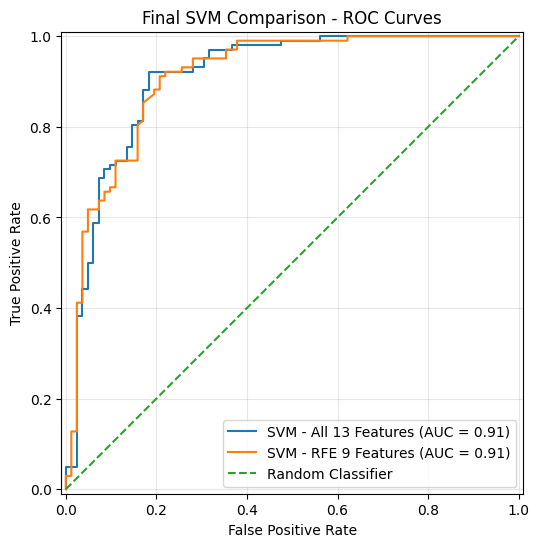

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

for name, (model, features) in models_to_compare.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test[features],
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Final SVM Comparison - ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [17]:
# final_comparison.to_csv(
#     "D:/1_Python Programmes/Projects/HDD/reports/svm_feature_comparison.csv",
#     index=True
# )

# print("Comparison saved successfully!")

Comparison saved successfully!
